# 02 — Baseline Portfolio

Build an **equal-weight** portfolio (same % in each stock) and compare it to **SPY**.

This is our benchmark strategy. Optimized portfolios later must be judged against this simple rule.

## 1. Setup and load prices

Load cached adjusted closes. Portfolio uses the 9 stocks; SPY is kept separate as the market benchmark.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data_loader import DEFAULT_BENCHMARK, DEFAULT_TICKERS, load_or_download

TICKERS = DEFAULT_TICKERS          # 9 stocks in the portfolio
BENCHMARK = DEFAULT_BENCHMARK      # SPY for comparison
TRADING_DAYS = 252

prices = load_or_download(tickers=TICKERS + [BENCHMARK], refresh=False)
stock_prices = prices[TICKERS]
spy_prices = prices[BENCHMARK]

print(stock_prices.shape)
stock_prices.head()

(1717, 9)


,AAPL,MSFT,NVDA,AMZN,KO,WMT,JPM,XOM,JNJ
Date,,,,,,,,,
2020-01-02,72.271545,151.544266,5.957138,94.900497,44.873505,36.203289,117.313950,52.606388,121.338539
2020-01-03,71.568916,149.657257,5.861788,93.748497,44.628689,35.883690,115.765793,52.183475,119.933678
2020-01-06,72.139168,150.044144,5.886369,95.143997,44.612366,35.810627,115.673767,52.584148,119.784081
2020-01-07,71.799934,148.676056,5.957635,95.343002,44.269634,35.478859,113.707253,52.153793,120.515602
2020-01-08,72.954926,151.044205,5.968809,94.598503,44.351234,35.357101,114.594269,51.367298,120.498932


## 2. Daily returns

Turn prices into **simple daily returns**: `r_t = P_t / P_{t-1} - 1`.

Equal-weight portfolio return each day = average of the 9 stock returns that day (`1/n` each).

In [5]:
# TODO: you type this next (returns + equal-weight portfolio)

stock_returns = stock_prices.pct_change().dropna()
spy_returns = spy_prices.pct_change().dropna()

stock_returns, spy_returns = stock_returns.align(spy_returns, join = 'inner', axis=0)

n_assets = len(TICKERS)
equal_weights = np.repeat(1 / n_assets, n_assets)
print("weights:", dict(zip(TICKERS, equal_weights.round(4))))


ew_returns = stock_returns.mean(axis=1)
ew_returns.name = "equal_weight"

print("ew days:", len(ew_returns))
ew_returns.head()

weights: {'AAPL': np.float64(0.1111), 'MSFT': np.float64(0.1111), 'NVDA': np.float64(0.1111), 'AMZN': np.float64(0.1111), 'KO': np.float64(0.1111), 'WMT': np.float64(0.1111), 'JPM': np.float64(0.1111), 'XOM': np.float64(0.1111), 'JNJ': np.float64(0.1111)}
ew days: 1716


Date
2020-01-03   -0.010824
2020-01-06    0.003652
2020-01-07   -0.003961
2020-01-08    0.001897
2020-01-09    0.010259
Name: equal_weight, dtype: float64

## 3. Performance metrics

We'll summarize return, risk, Sharpe ratio, and max drawdown for the equal-weight portfolio and for SPY.

In [6]:
# TODO: metrics
def performance_metrics(returns: pd.Series, trading_days: int = 252) -> dict:
    """Summary stats for a daily return series."""
    r = returns.dropna()
    ann_return = r.mean() * trading_days
    ann_vol = r.std() * np.sqrt(trading_days)
    sharpe = ann_return / ann_vol if ann_vol > 0 else np.nan

    # Wealth path starting at 1.0, then drawdowns from running peak
    wealth = (1 + r).cumprod()
    drawdown = wealth / wealth.cummax() - 1
    max_drawdown = drawdown.min()

    return {
        "ann_return": ann_return,
        "ann_vol": ann_vol,
        "sharpe": sharpe,
        "max_drawdown": max_drawdown,
    }

ew_stats = performance_metrics(ew_returns, TRADING_DAYS)
spy_stats = performance_metrics(spy_returns, TRADING_DAYS)

comparison = pd.DataFrame(
    {"equal_weight": ew_stats, "SPY": spy_stats}
).T

comparison.style.format({
    "ann_return": "{:.2%}",
    "ann_vol": "{:.2%}",
    "sharpe": "{:.2f}",
    "max_drawdown": "{:.2%}",
})

,ann_return,ann_vol,sharpe,max_drawdown
equal_weight,25.24%,19.74%,1.28,-29.19%
SPY,15.80%,19.96%,0.79,-33.72%


## 4. Comparison chart

Plot cumulative growth of $1 in the equal-weight portfolio vs $1 in SPY.

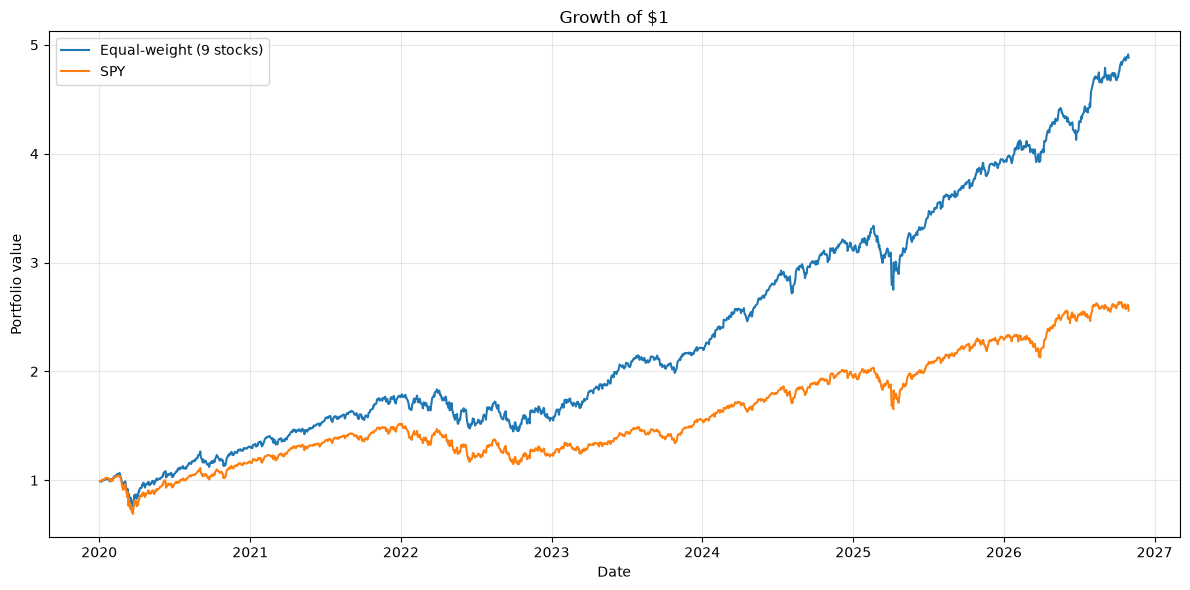

Final value — equal-weight: $4.88
Final value — SPY:          $2.56


In [7]:
ew_wealth = (1 + ew_returns).cumprod()
spy_wealth = (1 + spy_returns).cumprod()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(ew_wealth.index, ew_wealth, label="Equal-weight (9 stocks)")
ax.plot(spy_wealth.index, spy_wealth, label="SPY")
ax.set_title("Growth of $1")
ax.set_ylabel("Portfolio value")
ax.set_xlabel("Date")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Final value — equal-weight: ${:.2f}".format(ew_wealth.iloc[-1]))
print("Final value — SPY:          ${:.2f}".format(spy_wealth.iloc[-1]))